# 04_1 · Поправка на останні дні

У `04` поправка на 7 днів помітно допомогла простій фізиці: без неї — 363 Вт промаху, з нею — 335. Тут — що це за поправка, як її рахувати краще і чи може її рахувати модель.

**Як база і поправка працюють разом.** База (фізика чи LightGBM) з прогнозу погоди каже, скільки панелі *мали б* дати. Вона не знає, що панелі цього тижня брудні, в снігу чи в тіні. Поправка — одне число з останніх днів: скільки панелі справді дали від того, що обіцяла база. Прогноз = база × поправка.

Приклад: за тиждень база обіцяла 30 кВт·год, панелі дали 27 → поправка 0.9. Сьогодні база каже 1000 Вт о 12:00 → прогноз 900 Вт.

Поправка не вчиться і не знає погоди — вона ловить усе, що змінилось недавно: бруд, сніг, тінь, зношення, зміни в самій погодній моделі.

Перевірка та сама, що в `04`: 23 гру 2025 – 24 жов 2026, чисті години, база щомісяця перенавчається на минулому.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
import data_io as io, evaluate as ev
plt.rcParams.update({'figure.figsize': (11, 3.5), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', None)
df, train, test = ev.load()
clean = df[df.enough & ~df.clipped]; y = clean.pv_w; t = test.index
MONTHS = ['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру']

def compare(V, ref_name):
    ref = V[ref_name].reindex(t)
    rows = {k: {**ev.metrics(test.pv_w, v.reindex(t)),
                f'краще за «{ref_name}», % вибірок': '—' if k == ref_name else round(ev.daily_bootstrap(t, test.pv_w, v.reindex(t), ref) * 100)}
            for k, v in V.items()}
    r = pd.DataFrame(rows).T.sort_values('MAE, Вт'); r.index.name = 'поправка'
    for c in ('MAE, Вт', 'RMSE, Вт', 'зсув, Вт'):
        r[c] = r[c].astype(int)
    r['nMAE, %'] = r['nMAE, %'].astype(float)
    r.iloc[:, -1] = [v if v == '—' else int(v) for v in r.iloc[:, -1]]
    return r

base = ev.raw_all(df, ev.physics_fit_predict, ev.PHYSICS_COLS)
print('база: фізика панелей (найкращий метод з 04)')

база: фізика панелей (найкращий метод з 04)


## Як поправка міняється з часом

Нижче 1 — панелі дають менше, ніж обіцяє база; вище 1 — більше. Звичайна (7 днів порівну) і динамічна (свіжі дні важать більше, див. нижче).

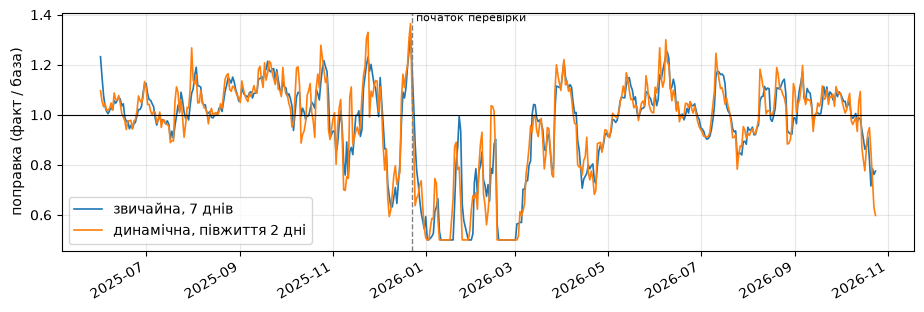

місяць,чер 2025,лип 2025,сер 2025,вер 2025,жов 2025,лис 2025,гру 2025,січ 2026,лют 2026,бер 2026,кві 2026,тра 2026,чер 2026,лип 2026,сер 2026,вер 2026,жов 2026
"звичайна, 7 днів",1.03,1.00,1.07,1.13,1.06,0.99,0.88,0.59,0.64,0.86,0.91,1.04,1.08,0.98,1.02,1.06,0.94
"динамічна, півжиття 2 дні",1.03,1.01,1.07,1.13,1.06,1.00,0.87,0.59,0.66,0.86,0.91,1.04,1.07,0.98,1.02,1.06,0.93


In [2]:
f7 = ev.recent_factor(base, y, 7); fw = ev.weighted_factor(base, y, 2)
day = base.index.tz_convert(io.TZ).normalize()
s = pd.DataFrame({'звичайна, 7 днів': f7.groupby(day).first(), 'динамічна, півжиття 2 дні': fw.groupby(day).first()})
s = s[s.index >= pd.Timestamp('2025-06-01', tz=io.TZ)]
ax = s.plot(lw=1.2); ax.axhline(1, c='k', lw=.8); ax.set_ylabel('поправка (факт / база)'); ax.set_xlabel('')
ax.axvline(pd.Timestamp(ev.SPLIT, tz=io.TZ), c='gray', ls='--', lw=1); ax.text(pd.Timestamp(ev.SPLIT, tz=io.TZ), ax.get_ylim()[1], ' початок перевірки', va='top', fontsize=8)
plt.show()
m = s.groupby([s.index.year, s.index.month]).mean().round(2)
m.index = [f'{MONTHS[mm - 1]} {yy}' for yy, mm in m.index]; m.index.name = 'місяць'; m.T

## Варіанти формули

Та сама база, міняється лише те, як рахувати число поправки:

- **звичайна, 7 / 14 днів** — Σ факт / Σ база за останні дні, усі дні порівну;
- **свіжі дні важать більше** — вага дня падає вдвічі кожні N днів (півжиття). Півжиття 2 дні: вчора 1, три дні тому 0.5, тиждень тому < 0.2;
- **окремо сонячні / хмарні години** — бруд шкодить прямому сонцю більше, ніж розсіяному; сонячно = індекс ясності ≥ 0.6;
- **окремо ранок / після полудня** — тінь буває лише в певні години.

Якщо в групі за тиждень мало енергії (< 20 % від усієї) — для неї береться спільна поправка.

In [3]:
sunny = np.where(clean.csi__forecast >= 0.6, 'сонячно', 'хмарно')
morning = np.where(clean.sun_azimuth < 180, 'ранок', 'після полудня')
F = {
    'без поправки': base,
    'звичайна, 7 днів': base * f7,
    'звичайна, 14 днів': base * ev.recent_factor(base, y, 14),
    'свіжі дні важать більше, півжиття 2 дні': base * fw,
    'свіжі дні важать більше, півжиття 4 дні': base * ev.weighted_factor(base, y, 4),
    'окремо сонячні / хмарні години, 7 днів': base * ev.group_factor(base, y, sunny, 7),
    'окремо ранок / після полудня, 7 днів': base * ev.group_factor(base, y, morning, 7),
}
compare(F, 'звичайна, 7 днів')

,"MAE, Вт","nMAE, %","RMSE, Вт","зсув, Вт","краще за «звичайна, 7 днів», % вибірок"
поправка,,,,,
"свіжі дні важать більше, півжиття 4 дні",331,27.3,517,23,99
"свіжі дні важать більше, півжиття 2 дні",332,27.4,518,27,96
"окремо ранок / після полудня, 7 днів",334,27.6,527,23,76
"звичайна, 7 днів",335,27.7,522,27,—
"звичайна, 14 днів",335,27.7,522,20,54
"окремо сонячні / хмарні години, 7 днів",337,27.8,520,9,37
без поправки,363,30.0,575,63,0


По місяцях, середній промах, Вт:

In [4]:
bm = pd.DataFrame({k: ev.by_month(t, test.pv_w, F[k].reindex(t)) for k in
                   ['без поправки', 'звичайна, 7 днів', 'свіжі дні важать більше, півжиття 2 дні']}).astype(int)
bm['виграш динамічної над звичайною, Вт'] = bm['звичайна, 7 днів'] - bm['свіжі дні важать більше, півжиття 2 дні']
bm.T

,гру 2025,січ 2026,лют 2026,бер 2026,кві 2026,тра 2026,чер 2026,лип 2026,сер 2026,вер 2026,жов 2026
без поправки,254,408,644,285,339,336,283,394,364,351,297
"звичайна, 7 днів",192,271,380,272,327,340,302,426,391,338,284
"свіжі дні важать більше, півжиття 2 дні",180,246,371,277,326,339,299,417,384,346,291
"виграш динамічної над звичайною, Вт",12,25,9,-5,1,1,3,9,7,-8,-7


## Модель поправки

Замість формули — LightGBM, який сам вирішує, на скільки поправити. Бачить: поправку за вчора, за 7 днів і динамічну, а також умови години (індекс ясності, частка розсіяної, висота і напрямок сонця, сніг, температура). Так він міг би навчитись, наприклад, «у сонячні години бруд з'їдає більше».

Два способи:
- **А: поверх бази** — прогнозує генерацію, знаючи базу і поправки;
- **Б: множник** — прогнозує саме число факт / база.

**Пастка («модель вгадує те, що вже знає»).** На першому році база прогнозує дні, на яких сама навчалась, тож там поправка ≈ 1 і нічого не означає — а на перевірці база вже помиляється по-справжньому. Модель поправки, навчена на першому році, вчиться не того. Тому є **чесний** варіант: модель поправки вчиться лише на днях, де база справді не бачила відповіді (з 23 гру 2025, щомісяця більше); поки таких днів мало — динамічна формула.

In [5]:
M = {'динамічна формула, півжиття 2 дні': F['свіжі дні важать більше, півжиття 2 дні'],
     'звичайна, 7 днів': F['звичайна, 7 днів']}
for kind, name in (('on_top', 'А: поверх бази'), ('multiplier', 'Б: множник')):
    M[f'модель {name}'] = ev.correction_model(df, base, kind)
    M[f'модель {name}, чесна'] = ev.correction_model(df, base, kind, honest=True)
compare(M, 'динамічна формула, півжиття 2 дні')

,"MAE, Вт","nMAE, %","RMSE, Вт","зсув, Вт","краще за «динамічна формула, півжиття 2 дні», % вибірок"
поправка,,,,,
модель Б: множник,303,25.1,507,35,100
модель А: поверх бази,310,25.6,516,59,100
"модель Б: множник, чесна",325,26.9,527,27,81
"динамічна формула, півжиття 2 дні",332,27.4,518,27,—
"звичайна, 7 днів",335,27.7,522,27,4
"модель А: поверх бази, чесна",341,28.2,553,31,18


## Те саме, коли база — LightGBM

LightGBM з `05` (20 ознак) уже знає погоду, сонце і сезон — поправці лишається менше роботи.

In [6]:
PARAMS = dict(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, random_state=0, verbose=-1)
fp_lgb = lambda X, yy, Xt: lgb.LGBMRegressor(**PARAMS).fit(X, yy).predict(Xt)
lbase = ev.raw_all(df, fp_lgb, ev.variants()['повний (20 ознак)'])
L = {'без поправки': lbase,
     'звичайна, 7 днів': lbase * ev.recent_factor(lbase, y, 7),
     'динамічна формула, півжиття 2 дні': lbase * ev.weighted_factor(lbase, y, 2),}
for kind, name in (('on_top', 'А: поверх бази'), ('multiplier', 'Б: множник')):
    L[f'модель {name}'] = ev.correction_model(df, lbase, kind)
    L[f'модель {name}, чесна'] = ev.correction_model(df, lbase, kind, honest=True)
compare(L, 'динамічна формула, півжиття 2 дні')

,"MAE, Вт","nMAE, %","RMSE, Вт","зсув, Вт","краще за «динамічна формула, півжиття 2 дні», % вибірок"
поправка,,,,,
"динамічна формула, півжиття 2 дні",302,25.0,502,16,—
"звичайна, 7 днів",306,25.3,505,15,2
без поправки,310,25.6,525,76,13
модель А: поверх бази,315,26.1,534,55,0
модель Б: множник,317,26.2,532,52,1
"модель А: поверх бази, чесна",332,27.4,552,38,0
"модель Б: множник, чесна",333,27.6,555,72,0


## Зведення: база × поправка

In [7]:
S = {'фізика + звичайна 7 днів (планка з 04)': F['звичайна, 7 днів'],
     'фізика + динамічна формула': F['свіжі дні важать більше, півжиття 2 дні'],
     'фізика + модель поправки А (не чесна)': M['модель А: поверх бази'],
     'LightGBM + звичайна 7 днів': L['звичайна, 7 днів'],
     'LightGBM + динамічна формула': L['динамічна формула, півжиття 2 дні'],}
compare(S, 'фізика + звичайна 7 днів (планка з 04)')

,"MAE, Вт","nMAE, %","RMSE, Вт","зсув, Вт","краще за «фізика + звичайна 7 днів (планка з 04)», % вибірок"
поправка,,,,,
LightGBM + динамічна формула,302,25.0,502,16,100
LightGBM + звичайна 7 днів,306,25.3,505,15,100
фізика + модель поправки А (не чесна),310,25.6,516,59,100
фізика + динамічна формула,332,27.4,518,27,96
фізика + звичайна 7 днів (планка з 04),335,27.7,522,27,—


In [8]:
pd.to_pickle({'physics': F, 'physics_models': M, 'lgb': L}, io.DATA / 'corrections.pkl')

## Висновки

1. **Поправка важлива для простої фізики, для LightGBM — менше.** Фізика: без поправки 363 Вт, з нею 332–335; LightGBM: без поправки 305, з нею 300. LightGBM уже знає сезон, і після очищення даних завищення в нього лише в окремі місяці.
2. **Головна робота поправки — зима.** Графік: улітку поправка ~1.0–1.08 (панелі дають як обіцяно), у січ–лют 2026 — **0.59–0.66**: сніг на панелях, ожеледиця після 26 січ. Перший рік такої зими не бачив — поправка ловить.
3. **Динамічна формула трохи краща за звичайну:** свіжі дні важать більше — фізика 335 → 332, LightGBM 304 → 300, краще у 96–97 % вибірок. Виграш — узимку (гру–січ +12…25 Вт): сніг ліг чи зійшов, і вчорашній день каже більше, ніж тиждень тому. 14 днів — не краще за 7.
4. **Розбивка на групи не допомогла:** окремо сонячні / хмарні чи ранок / після полудня — на рівні шуму.
5. **Модель поправки:** на базі «фізика» вона виграє (множник 304, чесна — 324 проти 332 у формули), бо бачить хмари й сонце і доробляє фізику до ML. На базі LightGBM — гірша за формулу в будь-якому варіанті (307–330): виправляти нічого, лише додає шум.
6. **Що беремо:** LightGBM + динамічна формула — **300 Вт** (25 % від середньої генерації). Щоденна модель поправки — у `04_2`, великі моделі — у `04_3`/`04_4`.